In [112]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from scipy.stats import bootstrap
import matplotlib.pyplot as plt

df = pd.read_csv("Cappuccino Index 2026 (public) - full_data.csv")

In [113]:
df.head()

,Currency,Hourly wage,Price per small cappuccino,Country,City,Urban classification,Hourly wage in GBP,Price per cappuccino in GBP
0,DKK - Danish Krone,140.00,90.00,Denmark,Copenhagen,Urban,15.99,10.28
1,CNY - Yuan Renminbi,30.00,86.00,China,Shenzhen,Urban,3.30,9.45
2,USD - US dollar,17.88,12.00,USA,West Richland,Suburban,13.25,8.90
3,CHF - Swiss Franc,26.70,9.00,Switzerland,St. Moritz,Rural,24.32,8.20
4,DKK - Danish Krone,140.00,65.00,Denmark,Copenhagen,Urban,15.99,7.43


In [114]:
model = LinearRegression()
model.fit(df[['Hourly wage in GBP']], df['Price per cappuccino in GBP'])
r_sq = model.score(df[['Hourly wage in GBP']], df['Price per cappuccino in GBP'])
print(f"coefficient of determination: {r_sq}")

coefficient of determination: 0.2280383514604577


## Bootstrap CI for price/wage ratio, per country

* Cappuccinos per hour are calculated for each observation and used to bootstrap intervals
* Regions with less than 5 observations are removed because the bootstrap intervals could falsely look tight.

In [115]:
df['ratio'] = df['Hourly wage in GBP'] / df['Price per cappuccino in GBP'] 
df = df.groupby('Country').filter(lambda x: len(x) >= 5)

def boot_ci(vals):
    #Boostrap function to calculate confidence intervals
    # res = bootstrap((vals,), np.mean, confidence_level=0.95, n_resamples=10_000, method='percentile', random_state=42)
    # return pd.Series({'n': len(vals), 'mean_ratio': vals.mean(), \
    #                   'ci_025': res.confidence_interval.low, \
    #                   'ci_975': res.confidence_interval.high})
    res = bootstrap((vals,), np.mean, confidence_level=1-(0.05/df['Country'].nunique()), n_resamples=10_000, method='percentile', random_state=42)
    return pd.Series({'n': len(vals), 'mean_ratio': vals.mean(), \
                      'ci_025': res.confidence_interval.low, \
                      'ci_975': res.confidence_interval.high})
ci_df = df.groupby('Country')['ratio'].apply(boot_ci).unstack()
ci_df['ci_width'] = ci_df['ci_975'] - ci_df['ci_025']
ci_df = ci_df.sort_values('mean_ratio').reset_index()
ci_df

,Country,n,mean_ratio,ci_025,ci_975,ci_width
0,India,11.0,0.349903,0.235248,0.436852,0.201604
1,Vietnam,6.0,0.369756,0.340894,0.406467,0.065573
2,Philippines,11.0,0.544303,0.412511,0.695216,0.282705
3,Mexico,24.0,0.852541,0.632467,1.137137,0.504670
4,Malaysia,18.0,0.895707,0.691985,1.193827,0.501842
5,Indonesia,8.0,0.905001,0.415522,2.435999,2.020476
6,Turkey,10.0,0.905271,0.477422,1.377139,0.899717
7,Argentina,22.0,1.012900,0.815338,1.214214,0.398876
8,Brazil,14.0,1.060752,0.779527,1.354869,0.575342
9,Colombia,6.0,1.217447,0.806967,1.669231,0.862264


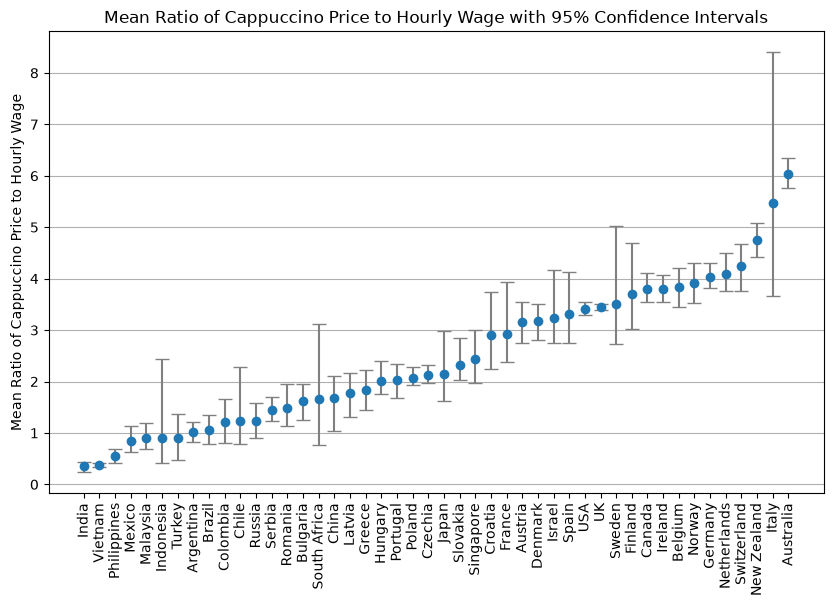

In [116]:
plt.figure(figsize=(10, 6))
plt.errorbar(ci_df['Country'], ci_df['mean_ratio'],
             yerr=[ci_df['mean_ratio'] - ci_df['ci_025'], ci_df['ci_975'] - ci_df['mean_ratio']],
             fmt='o', ecolor='gray', capsize=5, capthick=1)
plt.xticks(rotation=90)
plt.ylabel('Mean Ratio of Cappuccino Price to Hourly Wage')
plt.title('Mean Ratio of Cappuccino Price to Hourly Wage with 95% Confidence Intervals')
plt.grid(axis='y')

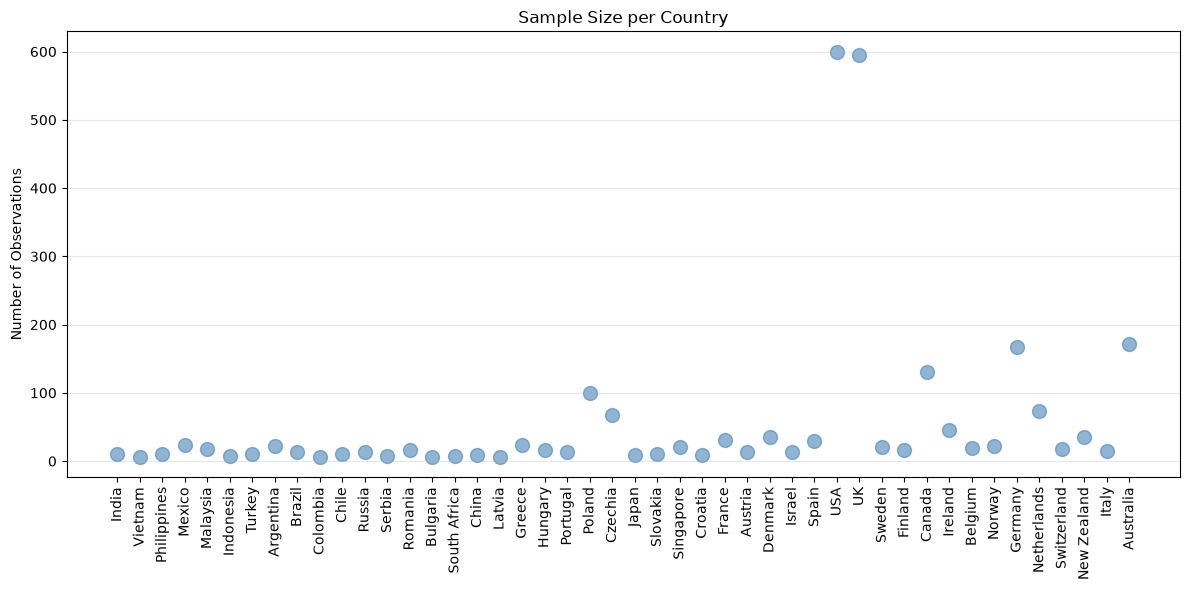

In [117]:
x = np.arange(len(ci_df))

# Create a dot plot showing the number of observations per country
plt.figure(figsize=(12, 6))
plt.scatter(x, ci_df['n'], s=100, alpha=0.6, color='steelblue')
plt.xticks(x, ci_df['Country'], rotation=90)
plt.ylabel('Number of Observations')
plt.title('Sample Size per Country')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

## Testing various claims 

## Bootstrapped CI for pairwise mean differences vs. Italy

Independently bootstrap-resample each country's `ratio` values (percentile method, same convention as the per-country `boot_ci` above) and take `mean(Italy) - mean(other)` on each resample to get a CI directly on the pairwise difference. Limited to Italy vs. the other 45 countries (rather than all 1035 pairs), so the Bonferroni-style divisor on `alpha` is 45 instead of 1035 — a much less extreme correction, which is also why `n_resamples` is bumped up modestly rather than needing the ~100k that the full 1035-pair version would've required.

In [118]:
groups = {c: g.to_numpy() for c, g in df.groupby('Country')['ratio']}

target_country = 'Italy'
other_countries = sorted(c for c in groups if c != target_country)
n_comparisons = len(other_countries)
confidence_level = 1 - (0.05 / n_comparisons)

def boot_diff_ci(a, b, confidence_level=confidence_level, n_resamples=20_000, random_state=42):
    res = bootstrap((a, b), lambda x, y: np.mean(x, axis=-1) - np.mean(y, axis=-1),
                     confidence_level=confidence_level, n_resamples=n_resamples,
                     method='percentile', random_state=random_state)
    return res.confidence_interval.low, res.confidence_interval.high

va = groups[target_country]
records = []
for b in other_countries:
    vb = groups[b]
    ci_low, ci_high = boot_diff_ci(va, vb)
    records.append({
        'country_a': target_country, 'country_b': b,
        'n_a': len(va), 'n_b': len(vb),
        'mean_diff': va.mean() - vb.mean(),
        'boot_ci_025': ci_low,
        'boot_ci_975': ci_high,
    })

boot_pairs_df = pd.DataFrame(records)
boot_pairs_df['significant'] = ~((boot_pairs_df['boot_ci_025'] <= 0) & (boot_pairs_df['boot_ci_975'] >= 0))
boot_pairs_df = boot_pairs_df.sort_values('mean_diff').reset_index(drop=True)
boot_pairs_df

,country_a,country_b,n_a,n_b,mean_diff,boot_ci_025,boot_ci_975,significant
0,Italy,Australia,15,171,-0.562460,-2.336908,2.241559,False
1,Italy,New Zealand,15,35,0.726139,-1.074191,3.536271,False
2,Italy,Switzerland,15,18,1.235692,-0.632529,4.030132,False
3,Italy,Netherlands,15,73,1.381754,-0.481005,4.143506,False
4,Italy,Germany,15,167,1.433405,-0.353907,4.147302,False
5,Italy,Norway,15,22,1.564223,-0.298654,4.318656,False
6,Italy,Belgium,15,19,1.637326,-0.177578,4.433902,False
7,Italy,Ireland,15,45,1.678397,-0.119712,4.432415,False
8,Italy,Canada,15,130,1.684721,-0.100621,4.463540,False
9,Italy,Finland,15,16,1.774117,-0.303123,4.700136,False


### Claim 1: "in second place, a little bit of a surprise. We go to Europe, to Italy! Just under 12 minutes"
James lists off countries, starting with Australia which has a narrow confidence interval (CI) that only overlaps with Italy's large CI. He really cannot confidently claim Australia has the highest Cappuccinos per hour when the Italian estimate is this uncertain. This uncertainty in Italy is because of the low number of observations. He then claims Australia and Italy are likely the highest because these countries have more competition between cafes. I think this could be an interesting claim to investigate. However due to the limited Italian data, this is only an exploratory analysis. Not a confident suggestion.

James also states Italy is number two which cannot confidently be claimed. With its confidence interval 95 percent of its sample means span from Finland's mean to Australia's.

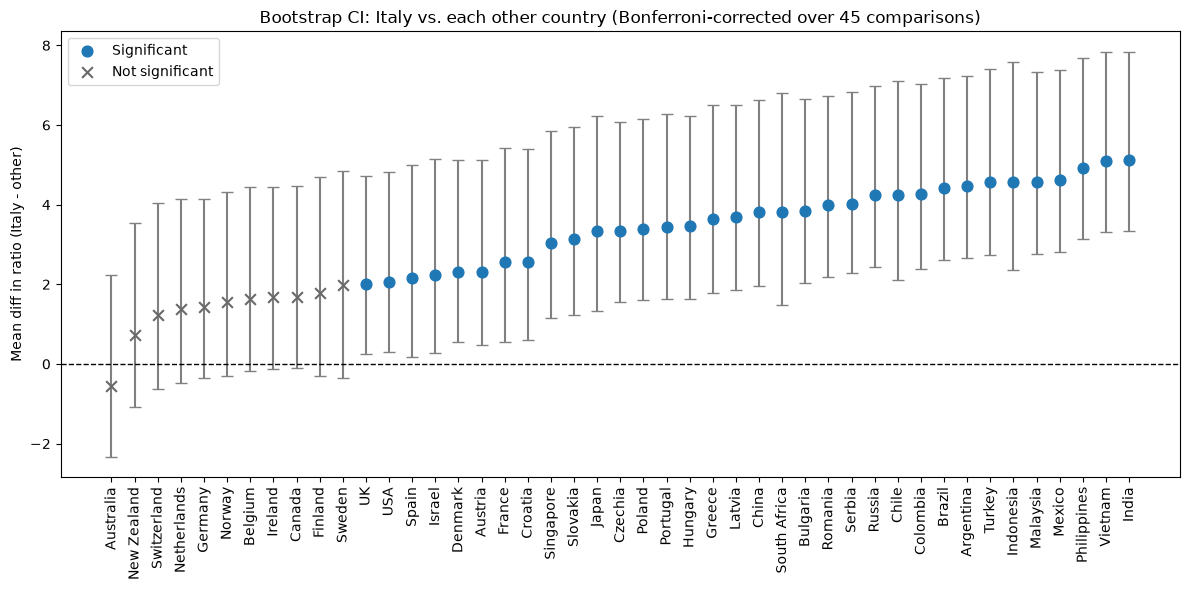

In [119]:
x = np.arange(len(boot_pairs_df))
sig_mask = boot_pairs_df['significant'].to_numpy()

plt.figure(figsize=(12, 6))
plt.errorbar(x, boot_pairs_df['mean_diff'],
             yerr=[boot_pairs_df['mean_diff'] - boot_pairs_df['boot_ci_025'],
                   boot_pairs_df['boot_ci_975'] - boot_pairs_df['mean_diff']],
             fmt='none', ecolor='gray', capsize=4, zorder=2)
plt.scatter(x[sig_mask], boot_pairs_df['mean_diff'][sig_mask], c='tab:blue', marker='o',
            s=60, zorder=3, label='Significant')
plt.scatter(x[~sig_mask], boot_pairs_df['mean_diff'][~sig_mask], c='dimgray', marker='x',
            s=60, zorder=3, label='Not significant')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xticks(x, boot_pairs_df['country_b'], rotation=90)
plt.ylabel(f'Mean diff in ratio ({target_country} - other)')
plt.title(f'Bootstrap CI: {target_country} vs. each other country '
          f'(Bonferroni-corrected over {n_comparisons} comparisons)')
plt.legend()
plt.tight_layout()

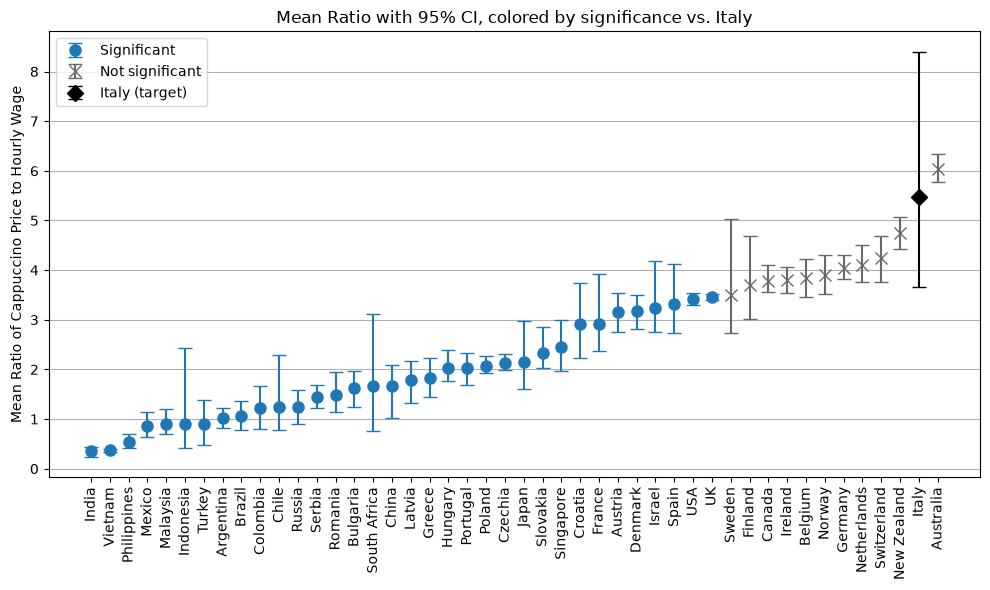

In [120]:
sig_map = boot_pairs_df.set_index('country_b')['significant']

ci_df_plot = ci_df.sort_values('mean_ratio').reset_index(drop=True)
x2 = np.arange(len(ci_df_plot))

target_mask = (ci_df_plot['Country'] == target_country).to_numpy()
sig_mask2 = ci_df_plot['Country'].map(sig_map).fillna(False).to_numpy() & ~target_mask
not_sig_mask2 = ~sig_mask2 & ~target_mask

plt.figure(figsize=(10, 6))
plt.errorbar(x2[sig_mask2], ci_df_plot['mean_ratio'][sig_mask2],
             yerr=[ci_df_plot['mean_ratio'][sig_mask2] - ci_df_plot['ci_025'][sig_mask2],
                   ci_df_plot['ci_975'][sig_mask2] - ci_df_plot['mean_ratio'][sig_mask2]],
             fmt='o', markersize=8, color='tab:blue', ecolor='tab:blue', capsize=5, capthick=1,
             label='Significant')
plt.errorbar(x2[not_sig_mask2], ci_df_plot['mean_ratio'][not_sig_mask2],
             yerr=[ci_df_plot['mean_ratio'][not_sig_mask2] - ci_df_plot['ci_025'][not_sig_mask2],
                   ci_df_plot['ci_975'][not_sig_mask2] - ci_df_plot['mean_ratio'][not_sig_mask2]],
             fmt='x', markersize=8, color='dimgray', ecolor='dimgray', capsize=5, capthick=1,
             label='Not significant')
plt.errorbar(x2[target_mask], ci_df_plot['mean_ratio'][target_mask],
             yerr=[ci_df_plot['mean_ratio'][target_mask] - ci_df_plot['ci_025'][target_mask],
                   ci_df_plot['ci_975'][target_mask] - ci_df_plot['mean_ratio'][target_mask]],
             fmt='D', markersize=8, color='black', ecolor='black', capsize=5, capthick=1,
             label=f'{target_country} (target)')
plt.xticks(x2, ci_df_plot['Country'], rotation=90)
plt.ylabel('Mean Ratio of Cappuccino Price to Hourly Wage')
plt.title(f'Mean Ratio with 95% CI, colored by significance vs. {target_country}')
plt.grid(axis='y')
plt.legend()
plt.tight_layout()